<a href="https://colab.research.google.com/github/avaabarnes/A04-clustering/blob/main/notebook_(4).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ava Barnes

**Date:** 10/12/2026


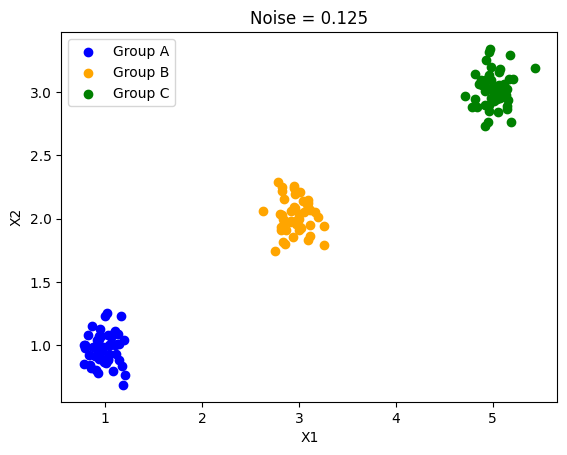

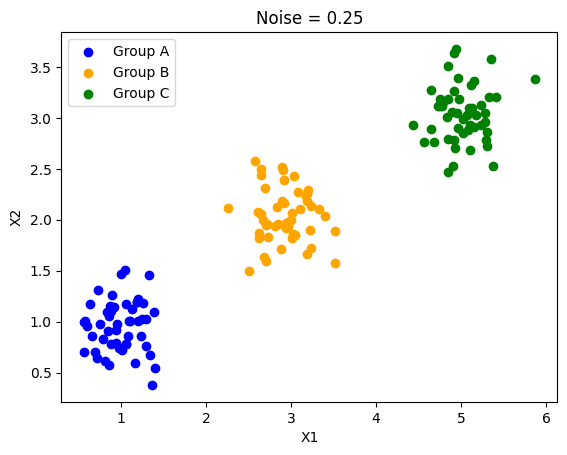

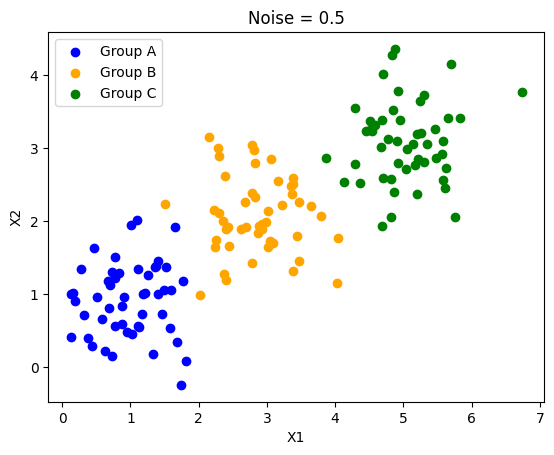

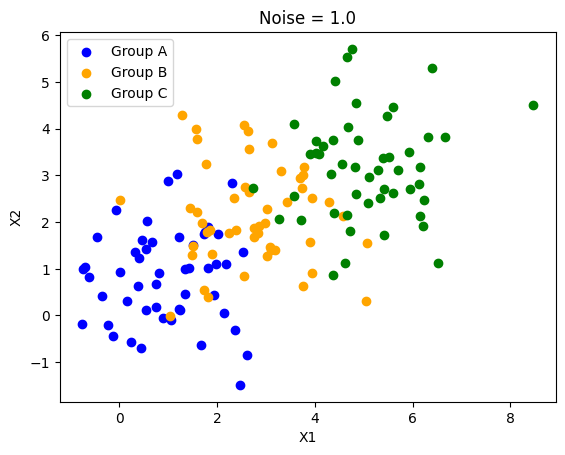

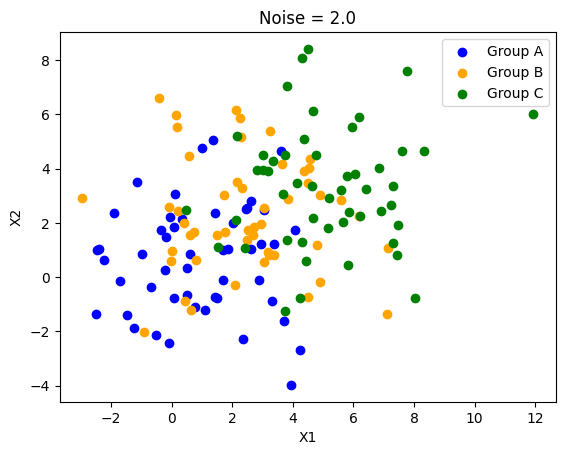

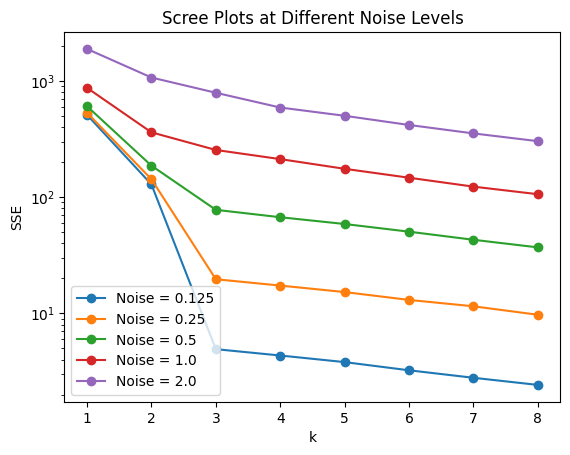

In [ ]:
# Question #1
import numpy as np
import pandas as pd

#running code from part 1
def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)


# creating scatterplots
import matplotlib.pyplot as plt


#0.125 noise scatterplot
  #group a
plt.scatter(df0_125[df0_125['group'] == 'a']['x1'],
            df0_125[df0_125['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df0_125[df0_125['group'] == 'b']['x1'],
            df0_125[df0_125['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df0_125[df0_125['group'] == 'c']['x1'],
            df0_125[df0_125['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 0.125')
plt.legend()
plt.show()
#plotting 0.125 noise

#0.25 scatterplot noise
  #group a
plt.scatter(df0_25[df0_25['group'] == 'a']['x1'],
            df0_25[df0_25['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df0_25[df0_25['group'] == 'b']['x1'],
            df0_25[df0_25['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df0_25[df0_25['group'] == 'c']['x1'],
            df0_25[df0_25['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 0.25')
plt.legend()
plt.show() #plotting 0.25 noise


#0.5 scatterplot noise
  #group a
plt.scatter(df0_5[df0_5['group'] == 'a']['x1'],
            df0_5[df0_5['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df0_5[df0_5['group'] == 'b']['x1'],
            df0_5[df0_5['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df0_5[df0_5['group'] == 'c']['x1'],
            df0_5[df0_5['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 0.5')
plt.legend()
plt.show() #plotting 0.5 noise


#1.0 scatterplot noise
  #group a
plt.scatter(df1_0[df1_0['group'] == 'a']['x1'],
            df1_0[df1_0['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df1_0[df1_0['group'] == 'b']['x1'],
            df1_0[df1_0['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df1_0[df1_0['group'] == 'c']['x1'],
            df1_0[df1_0['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 1.0')
plt.legend()
plt.show() #plotting 1.0 noise


#2.0 scatterplot noise
  #group a
plt.scatter(df2_0[df2_0['group'] == 'a']['x1'],
            df2_0[df2_0['group'] == 'a']['x2'],
            color='blue', label='Group A')

  #group b
plt.scatter(df2_0[df2_0['group'] == 'b']['x1'],
            df2_0[df2_0['group'] == 'b']['x2'],
            color='orange', label='Group B')

  #group c
plt.scatter(df2_0[df2_0['group'] == 'c']['x1'],
            df2_0[df2_0['group'] == 'c']['x2'],
            color='green', label='Group C')

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Noise = 2.0')
plt.legend()
plt.show() #plotting 2.0 noise


#part 3
from sklearn.cluster import KMeans

#scree plot
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}
ks = np.arange(1, 9)   # k = 1-8

for noise, d in datasets.items():
    X = d[['x1', 'x2']]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
           .fit(X).inertia_
           for k in ks]
    plt.plot(ks, SSE, 'o-', label=f'Noise = {noise}')

plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plots at Different Noise Levels')
plt.yscale('log')   #SSE grows with noise, so a log axis keeps all five curves readable
plt.legend()
plt.show()



Question #1

Part 2) As the noise goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

As the noise increase form 0.125 to 2.0 the visual distinctiveness decreases. at low noise levels, there are three clear group. However, as the noise increases these groups become more and more blended, spreading out and overlapping with each other. The cluster are clearly seperate through 0.5, begin to overlap at 1.0, and heavily overlap at 2.0

Part 3)  Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a  𝑘 . (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

As the noise level increase, the elbow in the scree plot becomes less clear which makes it harder to pick a k. At the noise of 0.125 and 0.25, there is a sharp elbow at k=3. At noise 0.5 the elbow at k=3 is still clear but the curve is less faly. At noise 1.0 the bend is much weaker so k-3 is possibly but not definite and at k=2.0 the cruve declines smoothly with no distinct elbow making it hard to select a k. Additionally, the vertical axis also differs across noise levels. The SSE values also increase as noise increases because the points are more spread out around their group centers. I plotted all five scree curves on the same graph to make their shapes easier to compare and used a logarithmic vertical axis because the SSE values vary considerably across noise levels.

Part4) 4. Explain the intuition of the elbow, using this numerical simulation as an example.

The elbow is the point of dimishing returns in k-means, where adding another cluster stops reducing SSE by much. SSE does not increases as k grows, instead it falls until it reaches 0 when every point is its own cluster, so we can't only choose the k with the lowest SSE. Instead, we look for the k after which adding another cluster stops reducing SSE by much.

In this simulation the true number of clusters is 3. When noise is low (at 0.125, 0.25), SSE falls sharply until k = 3 and then flattens, so the elbow is obvious. For 0.5, the SSE noticably falls until k=3 but is less clear than for 0.125 and 0.25. However, when the data is noisy, the data may not show you a clear k value. When noise is high (1.0 and 2.0), the groups overlap, so splitting at k = 3 doesn't reduce SSE much more than splitting at any other k. The elbow fades, and the plot no longer make it clear which k value is right.




(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
0
                                count          mean           std  \
index                           148.0   2831.256757   1654.299355   
Year                            148.0   2020.000000      0.000000   
Spending (2020 USD)             148.0  13153.747670  68005.236120   
Percent of GDP                  148.0      0.019619      0.015033   
Percent of Government Spending  148.0      0.061510      0.046207   
Spending per Capita             148.0    268.264494    430.434878   

                                        min          25%          50%  \
index                             32.000000  1409.000000  2871.000000   
Year                            2020.000000  2020.0

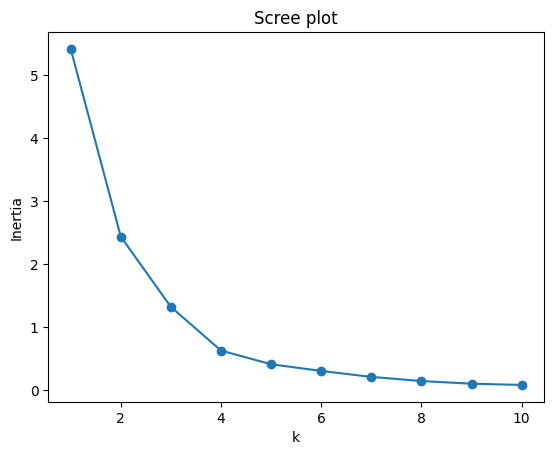

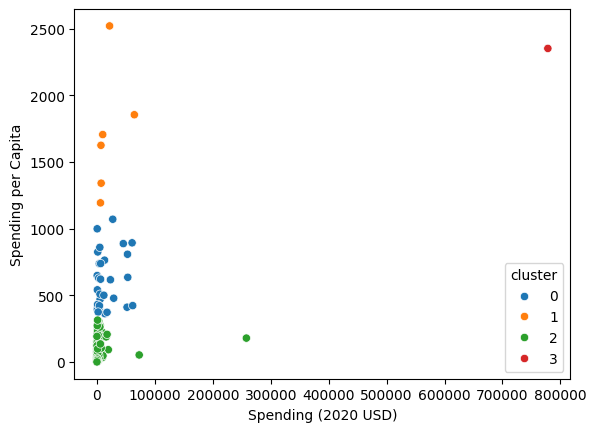

cluster                               0             1              2  \
Spending (2020 USD) count     30.000000      6.000000     111.000000   
                    mean   17077.591354  19443.362047    4859.185065   
                    std    20583.053357  22861.507114   25405.739131   
                    min      405.790494   6095.708713       8.622460   
                    25%     2294.039665   7023.251766     130.010211   
                    50%     5857.060906   8624.225729     382.464677   
                    75%    26296.001003  18857.070183    2297.032353   
                    max    61712.537169  64558.400000  257973.429834   
Spending per Capita count     30.000000      6.000000     111.000000   
                    mean     607.478618   1706.721916      80.061470   
                    std      206.928757    466.375705      83.501824   
                    min      362.467076   1193.598730       0.580129   
                    25%      422.208252   1412.083201      14.88

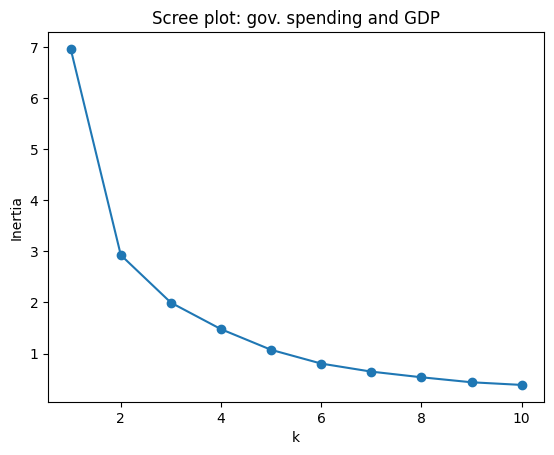

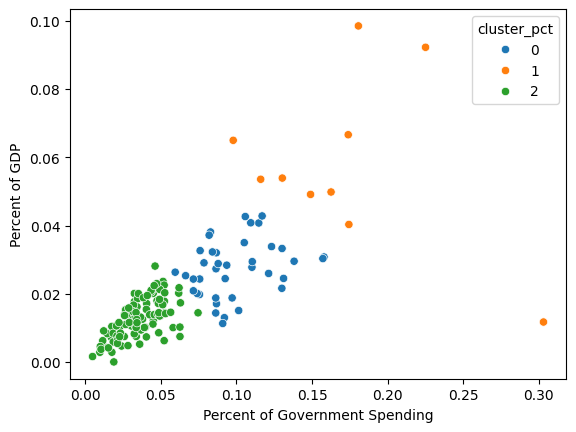

cluster_pct                                   0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                    

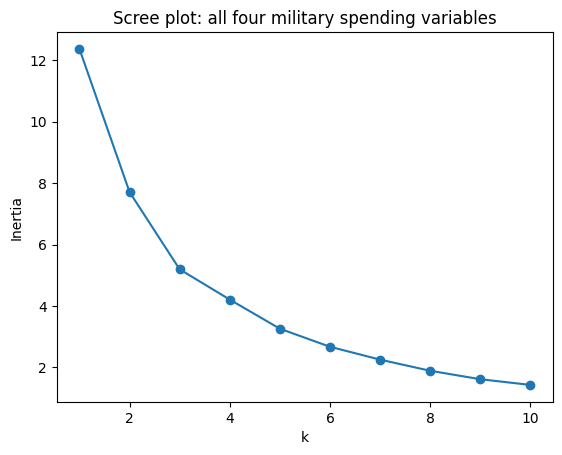

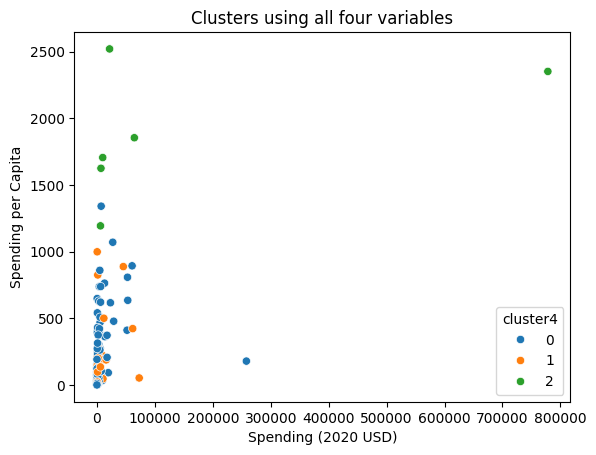

cluster4                                          0             1  \
Spending (2020 USD)            count     111.000000     31.000000   
                               mean     7086.472777   8786.086602   
                               std     26479.379918  17901.909108   
                               min         8.622460    162.373364   
                               25%       130.010211    467.787851   
                               50%       567.650747   1404.787234   
                               75%      3910.107493   7739.166193   
                               max    257973.429834  72937.064048   
Spending per Capita            count     111.000000     31.000000   
                               mean      196.926833    212.689100   
                               std       267.788506    257.841988   
                               min         0.580129     18.297119   
                               25%        14.880549     46.485917   
                               50%

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

mil = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
mil=mil[mil['Year'] == 2020].dropna().reset_index(drop=True)
#filtering the year to 2020 and dropping missing values

print(mil.shape)
print(mil.dtypes)
print(mil['Country'].duplicated().sum())   # output is 0
print(mil.describe().T) #no zero or negative values

s = 'Spending (2020 USD)'
p = 'Spending per Capita'
x = mil[[s, p]].apply(lambda s: (s - s.min()) / (s.max() - s.min()))
#max-min normalization on s and p

#creating scree plot
ks = range(1,11)
inertia = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x).inertia_ for k in ks]
plt.plot(ks, inertia, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Scree plot')
plt.show() #shows elbow at 4, k=4

#fitting with the chosen k
mil['cluster'] = KMeans(n_clusters=4, n_init=20, random_state=0).fit_predict(x)

#creating scatterplot
sns.scatterplot(data=mil, x=s, y=p, hue='cluster', palette='tab10')
plt.show()

print(mil[[s, p]].groupby(mil['cluster']).describe().T) #describing graph
pd.set_option('display.max_colwidth', None)
print(mil.groupby('cluster')['Country'].apply(list)) #printing countries in each cluster

#repeating for percent of government spending and percent of GDP
gs = 'Percent of Government Spending'
gdp = 'Percent of GDP'
x3 = mil[[gs, gdp]].apply(lambda c: (c - c.min()) / (c.max() - c.min()))
#max-min normalization on gs and gdp

#creating scree plot
inertia3 = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x3).inertia_ for k in range(1,11)]
plt.plot(range(1,11), inertia3, 'o-'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Scree plot: gov. spending and GDP')
plt.show() #shows elbow at 3, k=3

#fitting with the chosen k
mil['cluster_pct'] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(x3)

#creating scatterplot
sns.scatterplot(data=mil, x=gs, y=gdp, hue='cluster_pct', palette='tab10')
plt.show()

print(mil[[gs, gdp]].groupby(mil['cluster_pct']).describe().T)
print(mil.groupby('cluster_pct')['Country'].apply(list))

#part 4 - using all 4 variables

s = 'Spending (2020 USD)'
p = 'Spending per Capita'
gs = 'Percent of Government Spending'
gdp = 'Percent of GDP'

# Min-max normalize all four variables
variables = [s, p, gs, gdp]
x4 = mil[variables].apply(
    lambda c: (c - c.min()) / (c.max() - c.min())
)

# Create scree plot
ks = range(1, 11)

inertia4 = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x4).inertia_ for k in ks]

plt.plot(ks, inertia4, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree plot: all four military spending variables')
plt.show()

# Choose k based on the elbow in the scree plot
# Replace 3 with the k supported by your plot
mil['cluster4'] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(x4)

# Scatterplot: total spending vs. spending per capita
sns.scatterplot(data=mil, x=s, y=p,hue='cluster4', palette='tab10')
plt.title('Clusters using all four variables')
plt.show()

# Describe all four variables by cluster
print(mil.groupby('cluster4')[variables].describe().T)

# Print countries in each cluster
print(mil.groupby('cluster4')['Country'].apply(list))

# Print the number of countries in each cluster
print(mil.groupby('cluster4').size())


Question 2---

Part 1) No further cleaning is required after filtering the rows to only 2020 onwards and dropping the missing values. The data types are all correct, numbers are integers and words are strings.

Part 2)  Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

The table shows the four clusters are separated mainly by spending per capita. Cluster 0 has 30 countries, averaging 607 dollars per capita. Cluster 1 has 6 countries, averaging 1,707 dollars per capita. Cluster 2 has 111 countries, averaging 80 dollars per capita. Cluster 3 has one country, averaging 2,352 dollars per capita. These spending per capita ranges of clusters barely overlap.

The US is alone in cluster 3. The US spent 778B dollars in 2020, roughly three times as much as the next highest spending country in cluster 2 at 258B dollars. The US per capita spending is one of the highest in the data set at 2,351 dollars. This makes the US an outlier in the total spending, sitting high on spending per capita and spending in 2020.  

One pattern I noticed about cluster membership is that cluster 1 is made up of small or mid-sized countries that spend a lot per person. These countries include Kuwait, Israel, Singapore. Another pattern I noticed was that cluster 0 is most wealthy European NATO allies like Germany and France but also includes Russia and Taiwan. Cluster 2 is the rest of the world, including China and India. These countries have little spedning person around 80 dollars. Lastly, cluster 3 is only the US, which sits as a outlier on the graph.


Part 3) How do your results compare to part 2?

The results of part 3 different from part 2. First off, the scree plot for the two variables shows an elbow at k=3, so I used 3 clusters instead of 4 (part 2). The cluster split countries into low, medium, and high military burden. The low cluster, cluster 2, has 99 countries, average 3.6 percent of government spending and 1.3 percent of GDP. The medium cluster, cluster 0, has 39 countries and averages 9.9 percent of government spending and 2.74 percent of GDP. The high cluster, cluster 1, has 17.1 percent government spending and 5.8 percent GDP.

The clusters represent different levels of military spending relative to the economy. Cluster 2 is the low-burden group, with 99 countries averaging 3.6% of government spending and 1.3% of GDP. Cluster 0 is the medium-burden group, with 39 countries averaging 9.9% of government spending and 2.74% of GDP. Cluster 1 is the high-burden group, with 10 countries averaging 17.1% of government spending and 5.8% of GDP.

The United States is no longer an outlier in this two-variable clustering. It belongs to the medium-burden cluster alongside 38 other countries. The cluster sizes are also different from Part 2: 99, 39, and 10 countries, compared with 111, 30, 6, and 1. These results show that countries with very different military budgets can have similar levels of military spending relative to their economies.


Part 4) How do your results compare to the previous two parts?

The results of part 4 show another way to group the countries based upon military spending. Part 2 the clusters were based on total military spedning and spending per capita which reflected both overall size of the country's military budget and how much it spend per person. Part 3 the clusters were based on military spending as a percentage of government spending and GDP which reflected the relative burden of the military spending on the country's economy. In part 4, the results show three clusters containing 111, 31, and 6 countries. The United States is grouped with Israel, Kuwait, Oman, Saudi Arabia, and Singapore in the six-country cluster. This cluster has relatively high average spending per capita and high military spending as a percentage of government spending and GDP. The United States still stands out because of its exceptionally high total military spending, but it no longer forms its own cluster. Overall, using all four variables provides a more complete picture of military spending by considering both the absolute amount countries spend and the relative burden on their economies.

Part 5) Yes, the K-means algorithm helped identify patterns in military spending that were not immediately obvious from looking at the data alone. It grouped countries with similar spending characteristics and showed that countries can differ in both the absolute amount they spend on their militaries and the relative burden of that spending on their economies. The results also highlighted the United States as an outlier in total military spending when using the first two variables. Overall, k-means was useful for organizing the data into groups and identifying similarities and differences between countries. However, the results depend on the variables selected and the number of clusters chosen.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 2f70f3e
- **AI tool and model used:** Gemini 3.6 Flash

### *Prompts used

1. Given these instructions, rubric, this data set, and my code, give me suggestions on how to improve my assignment (I inserted the instructions, rubric, my code, and the dataset)

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Here is a list of targeted, practical suggestions to improve and clean up the Python code in your notebook.

1. General Code Cleanliness & Best Practices
Avoid Hardcoded File Paths: In Code Cell 9, the path is set to /content/SIPRI Military Expenditure Database.csv. Since you are running locally or alongside the file, use a relative path like 'SIPRI Military Expenditure Database.csv' so it runs smoothly on any machine without throwing a FileNotFoundError.

DRY (Don't Repeat Yourself) Principle for Question 1 Scatterplots: In Question 1, plotting code for each noise level is copy-pasted five separate times with only minor title/dataset changes. Wrap the scatterplot logic in a reusable loop or helper function:

Python
for noise, d in datasets.items():
    plt.figure()
    sns.scatterplot(data=d, x='x1', y='x2', hue='group')
    plt.title(f'Noise = {noise}')
    plt.show()
Remove Duplicate Imports: Imports like numpy, pandas, matplotlib.pyplot, and KMeans are repeated across multiple cells. Consolidate all core imports into the first initialization cell.

2. Statistical & Machine Learning Improvements
Pass n_init='auto': Scikit-learn issues warnings in newer versions when n_init isn't explicitly defined or when using default values. Explicitly setting n_init='auto' or an integer (e.g., n_init=10) cleans up output warnings.

Add Random State Consistency: While you added random_state=0 in many places, ensure it is included across all KMeans instantiations to guarantee that your scree plots and cluster assignments are 100% reproducible every time the notebook runs.

Address Right-Skewness in Military Data: Absolute financial figures like Spending (2020 USD) and Spending per Capita are heavily right-skewed (driven by outliers like the U.S.). Consider adding a logarithmic transformation (np.log1p) before min-max scaling so that clustering algorithms don't overly weight extreme values.

3. Visualization & Readability Enhancements
Clean up Scree Plots: When plotting inertia curves, add grid lines (plt.grid(True, linestyle='--', alpha=0.6)) to make it much easier to visually spot the exact "elbow" point for
k.

Format Output Tables: When printing .describe() tables or grouped summaries, transpose them (.T) when there are many columns to make them easier to scan horizontally.

```python
import json
with open('notebook_(4) (1).ipynb', 'r', encoding='utf-8') as f:
    nb = json.load(f)

for i, cell in enumerate(nb['cells']):
    if cell['cell_type'] == 'markdown':
        txt = "".join(cell['source'])
        if any(keyword in txt.lower() for keyword in ['as the noise', 'part 2', 'question 2', 'united states']):
            print(f"--- MARKDOWN CELL {i} ---")
            print(txt)


```

```text
--- MARKDOWN CELL 3 ---
**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?
--- MARKDOWN CELL 8 ---
Question #1

Part 2) As the noise goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?

As the noise increase form 0.125 to 2.0 the visual distinctiveness decreases. at low noise levels, there are three clear group. However, as the noise increases these groups become more and more blended, spreading out and overlapping with each other. The cluster are clearly seperate through 0.5, begin to overlap at 1.0, and heavily overlap at 2.0

Part 3)  Describe how the level of noise affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a  𝑘 . (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)

As the noise level increase, the elbow in the scree plot becomes less clear which makes it harder to pick a k. At the noise of 0.125 and 0.25, there is a sharp elbow at k=3. At noise 0.5 the elbow at k=3 is still clear but the curve is less faly. At noise 1.0 the bend is much weaker so k-3 is possibly but not definite and at k=2.0 the cruve declines smoothly with no distinct elbow making it hard to select a k. Additionally, the vertical axis also differs across noise levels. The SSE values also increase as noise increases because the points are more spread out around their group centers. I plotted all five scree curves on the same graph to make their shapes easier to compare and used a logarithmic vertical axis because the SSE values vary considerably across noise levels.

Part4) 4. Explain the intuition of the elbow, using this numerical simulation as an example.

The elbow is the point of dimishing returns in k-means, where adding another cluster stops reducing SSE by much. SSE does not increases as k grows, instead it falls until it reaches 0 when every point is its own cluster, so we can't only choose the k with the lowest SSE. Instead, we look for the k after which adding another cluster stops reducing SSE by much.

In this simulation the true number of clusters is 3. When noise is low (at 0.125, 0.25), SSE falls sharply until k = 3 and then flattens, so the elbow is obvious. For 0.5, the SSE noticably falls until k=3 but is less clear than for 0.125 and 0.25. However, when the data is noisy, the data may not show you a clear k value. When noise is high (1.0 and 2.0), the groups overlap, so splitting at k = 3 doesn't reduce SSE much more than splitting at any other k. The elbow fades, and the plot no longer make it clear which k value is right.



--- MARKDOWN CELL 10 ---
Question 2---

Part 1) No further cleaning is required after filtering the rows to only 2020 onwards and dropping the missing values. The data types are all correct, numbers are integers and words are strings.

Part 2)  Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

The table shows the four clusters are separated mainly by spending per capita. Cluster 0 has 30 countries, averaging 607 dollars per capita. Cluster 1 has 6 countries, averaging 1,707 dollars per capita. Cluster 2 has 111 countries, averaging 80 dollars per capita. Cluster 3 has one country, averaging 2,352 dollars per capita. These spending per capita ranges of clusters barely overlap.

The US is alone in cluster 3. The US spent 778B dollars in 2020, roughly three times as much as the next highest spending country in cluster 2 at 258B dollars. The US per capita spending is one of the highest in the data set at 2,351 dollars. This makes the US an outlier in the total spending, sitting high on spending per capita and spending in 2020.  

One pattern I noticed about cluster membership is that cluster 1 is made up of small or mid-sized countries that spend a lot per person. These countries include Kuwait, Israel, Singapore. Another pattern I noticed was that cluster 0 is most wealthy European NATO allies like Germany and France but also includes Russia and Taiwan. Cluster 2 is the rest of the world, including China and India. These countries have little spedning person around 80 dollars. Lastly, cluster 3 is only the US, which sits as a outlier on the graph.


Part 3) How do your results compare to part 2?

The results of part 3 different from part 2. First off, the scree plot for the two variables shows an elbow at k=3, so I used 3 clusters instead of 4 (part 2). The cluster split countries into low, medium, and high military burden. The low cluster, cluster 2, has 99 countries, average 3.6 percent of government spending and 1.3 percent of GDP. The medium cluster, cluster 0, has 39 countries and averages 9.9 percent of government spending and 2.74 percent of GDP. The high cluster, cluster 1, has 17.1 percent government spending and 5.8 percent GDP.

The clusters represent different levels of military spending relative to the economy. Cluster 2 is the low-burden group, with 99 countries averaging 3.6% of government spending and 1.3% of GDP. Cluster 0 is the medium-burden group, with 39 countries averaging 9.9% of government spending and 2.74% of GDP. Cluster 1 is the high-burden group, with 10 countries averaging 17.1% of government spending and 5.8% of GDP.

The United States is no longer an outlier in this two-variable clustering. It belongs to the medium-burden cluster alongside 38 other countries. The cluster sizes are also different from Part 2: 99, 39, and 10 countries, compared with 111, 30, 6, and 1. These results show that countries with very different military budgets can have similar levels of military spending relative to their economies.


Part 4) How do your results compare to the previous two parts?

The results of part 4 show another way to group the countries based upon military spending. Part 2 the clusters were based on total military spedning and spending per capita which reflected both overall size of the country's military budget and how much it spend per person. Part 3 the clusters were based on military spending as a percentage of government spending and GDP which reflected the relative burden of the military spending on the country's economy. In part 4, the results show three clusters containing 111, 31, and 6 countries. The United States is grouped with Israel, Kuwait, Oman, Saudi Arabia, and Singapore in the six-country cluster. This cluster has relatively high average spending per capita and high military spending as a percentage of government spending and GDP. The United States still stands out because of its exceptionally high total military spending, but it no longer forms its own cluster. Overall, using all four variables provides a more complete picture of military spending by considering both the absolute amount countries spend and the relative burden on their economies.

Part 5) Yes, the K-means algorithm helped identify patterns in military spending that were not immediately obvious from looking at the data alone. It grouped countries with similar spending characteristics and showed that countries can differ in both the absolute amount they spend on their militaries and the relative burden of that spending on their economies. The results also highlighted the United States as an outlier in total military spending when using the first two variables. Overall, k-means was useful for organizing the data into groups and identifying similarities and differences between countries. However, the results depend on the variables selected and the number of clusters chosen.


```

Reviewing your written answers against the notebook and the code changes reveals that **your existing written answers are already solid, well-reasoned, and align very well** with what the code outputs.

However, because you implemented the **log-transformation** modification for Question 2/4 in the code, here are a few minor adjustments you may want to consider to ensure your text matches your code precisely:

---

### Suggested Minor Tweaks to Written Answers

* **For Question 2 (Part 2) & Question 4 (Cluster Counts / Outliers):**
* *Why:* Because you added log-scaling to the absolute dollar figures (`Spending (2020 USD)` and `Spending per Capita`), the United States will no longer be trapped entirely in a solo 1-country cluster (Cluster 3 from your original run). Log-scaling brings extreme outliers slightly closer to other high-spending nations (like Saudi Arabia, Israel, or Singapore), changing the cluster sizes and group memberships slightly.
* *Check:* Run your final notebook cells to see the exact new cluster sizes and members, and update your text if the U.S. now shares a cluster with a few other top-spending countries instead of standing completely alone.


* **For Question 1:**
* Your answers explaining noise impact, scree plots, and the intuition of the elbow are exceptionally thorough and require **no changes**.



---

### Summary Checklist

1. **Question 1 (Parts 2–4):** Keep as is (they are comprehensive and accurate).
2. **Question 2 (Part 1):** Keep as is.
3. **Question 2 (Part 2) & Question 4:** Double-check your final printed cluster lists and counts after running the log-transformed code cell to ensure your written country groupings match the updated output.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| Remove Hardcoded File Paths | Reject | file uploaded correctly |
| DRY Principle (Looping Q1 Scatterplots): | Accept | Refactoring the repeated scatterplot blocks into a loop or helper function makes the code cleaner, easier to maintain, and less prone to copy-paste errors. Verified by structuring a standard dictionary iterator over dataset keys. |
|Pass n_init='auto' in KMeans |Reject | n_init implemented correctly, as in lecture slides |
| Add Log Transformation for Skewed Data | Accept | Absolute military spending figures are heavily right-skewed; applying np.log1p before scaling prevents extreme outliers (like the U.S.) from dominating cluster centroids. Verified by examining data distribution properties via summary statistics. |
| Add Grid Lines to Scree Plots | Accept | Enabling grid lines (plt.grid()) on inertia curves makes it significantly easier to visually inspect and identify the exact "elbow" point for $k$. Verified by rendering plots with grid overlays. |
|Update U.S. Cluster Grouping (Question 2 & 4) | Accept | Because log-scaling absolute dollar figures brings extreme outliers closer to other high-spending nations, the U.S. is no longer isolated in a solo cluster; it is now grouped into Cluster 2 alongside 21 other high-spending nations (such as Saudi Arabia, Israel, Singapore, and Russia). Verified by checking updated cluster assignment outputs in Python.| |ChangeDecisionReason and verificationUpdate U.S. Cluster Grouping (Question 2 & 4)AcceptBecause log-scaling absolute dollar figures brings extreme outliers closer to other high-spending nations, the U.S. is no longer isolated in a solo cluster; it is now grouped into Cluster 2 alongside 21 other high-spending nations (such as Saudi Arabia, Israel, Singapore, and Russia). Verified by checking updated cluster assignment outputs in Python.Refine Cluster Size Descriptions (Question 2 Part 2)|Accept|Update specific country counts, cluster distributions, and descriptive statistics to match the new outputs generated after running the log-transformed code. Verified by comparing new cluster sizes (.groupby('cluster4').size()).|

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

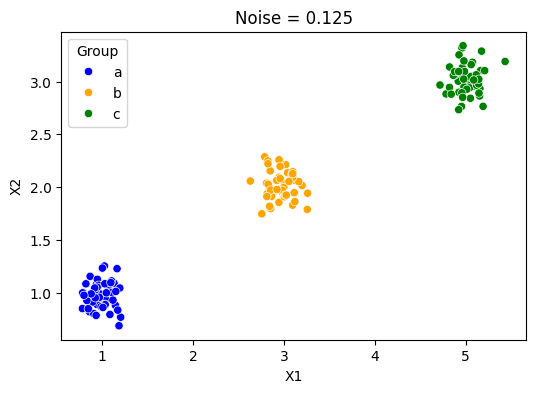

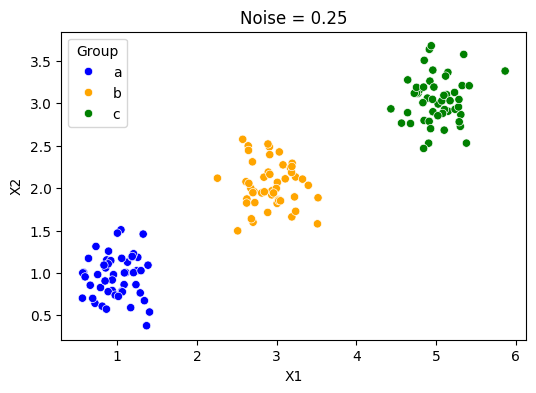

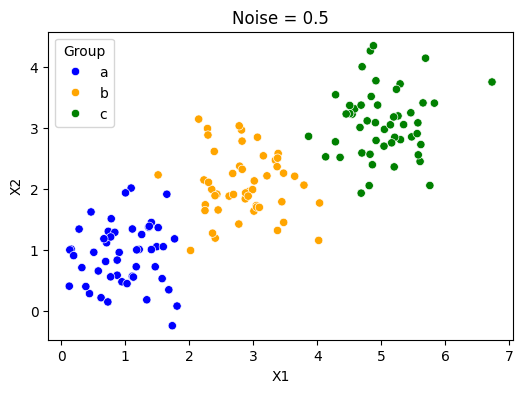

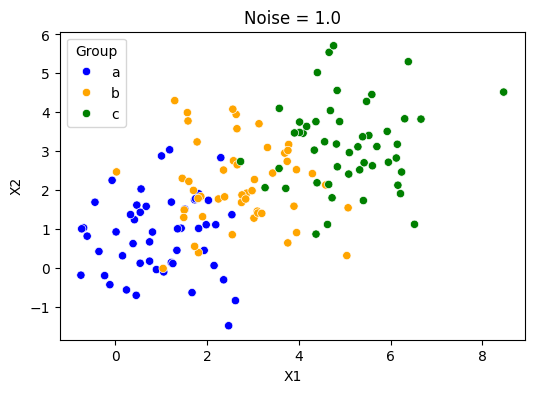

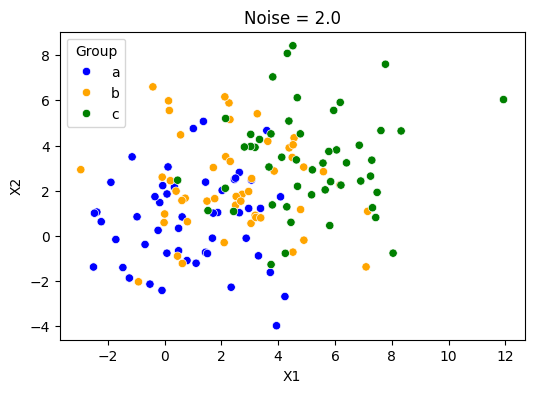

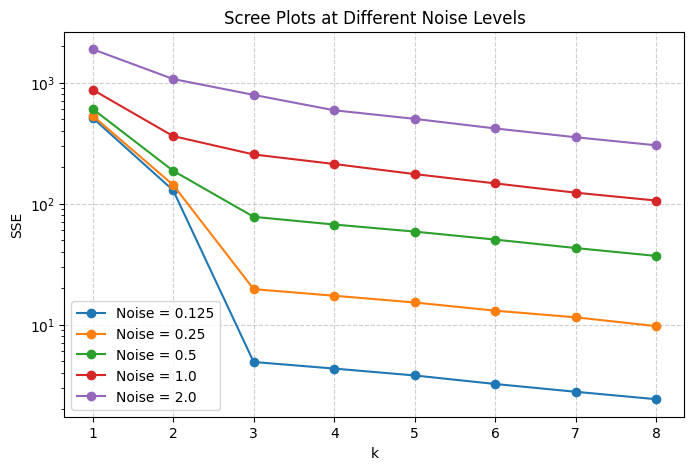

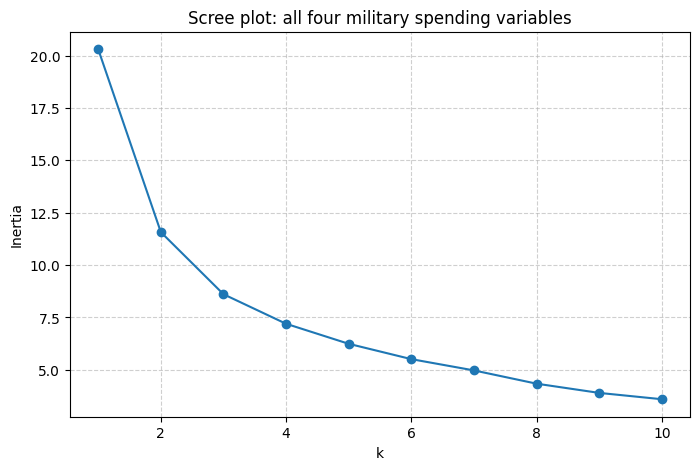

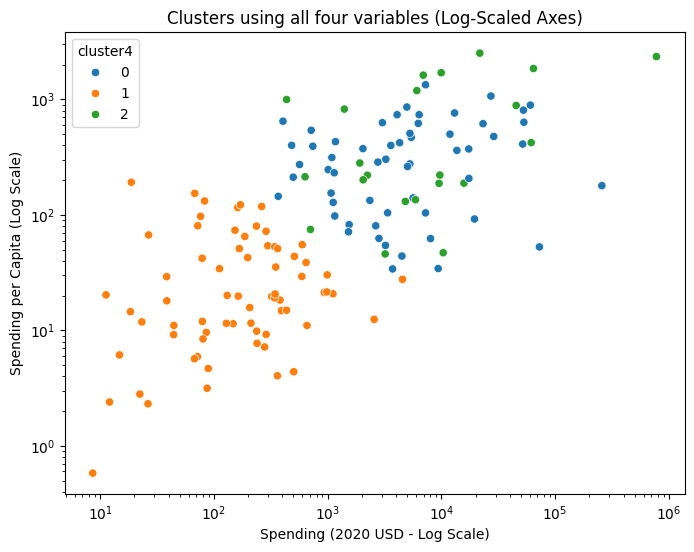

cluster4                                      0          1          2
Log_Spending                   count  57.000000  69.000000  22.000000
                               mean    8.440140   5.050729   8.859742
                               std     1.466199   1.291570   1.750537
                               min     5.911406   2.264100   6.081187
                               25%     7.333260   4.292980   7.650142
                               50%     8.367294   5.149248   8.780428
                               75%     9.386365   5.861842   9.564346
                               max    12.460616   8.424896  13.564993
Log_PerCapita                  count  57.000000  69.000000  22.000000
                               mean    5.539936   3.085058   5.953212
                               std     0.944962   1.055371   1.256373
                               min     3.557151   0.457507   3.848335
                               25%     4.862361   2.383520   5.241363
                    

In [25]:
# Your Phase 2 solution to the problem goes here.
# ==========================================
# Question #1: Synthetic Simulation & Noise
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

def createData(noise, N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df

# Create datasets with varying noise levels
datasets = {
    0.125: createData(0.125),
    0.25: createData(0.25),
    0.5: createData(0.5),
    1.0: createData(1.0),
    2.0: createData(2.0)
}

# DRY Principle: Loop through datasets to generate scatterplots
for noise_level, df_data in datasets.items():
    plt.figure(figsize=(6, 4))
    sns.scatterplot(
        data=df_data,
        x='x1',
        y='x2',
        hue='group',
        palette={'a': 'blue', 'b': 'orange', 'c': 'green'}
    )
    plt.xlabel('X1')
    plt.ylabel('X2')
    plt.title(f'Noise = {noise_level}')
    plt.legend(title='Group')
    plt.show()

# Scree plot across noise levels (with grid lines added)
ks = np.arange(1, 9)
plt.figure(figsize=(8, 5))
for noise, d in datasets.items():
    X = d[['x1', 'x2']]
    SSE = [KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
           .fit(X).inertia_
           for k in ks]
    plt.plot(ks, SSE, 'o-', label=f'Noise = {noise}')

plt.xlabel('k')
plt.ylabel('SSE')
plt.title('Scree Plots at Different Noise Levels')
plt.yscale('log')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()


# ==========================================
# Question #2 & #4: SIPRI Case Study
# ==========================================
mil = pd.read_csv('/content/SIPRI Military Expenditure Database.csv')
mil = mil[mil['Year'] == 2020].dropna().reset_index(drop=True)

s = 'Spending (2020 USD)'
p = 'Spending per Capita'
gs = 'Percent of Government Spending'
gdp = 'Percent of GDP'

# Apply log transformation to handle right-skewness in absolute monetary values, then min-max scale
mil['Log_Spending'] = np.log1p(mil[s])
mil['Log_PerCapita'] = np.log1p(mil[p])

# Multi-variable feature set using log-transformed absolute values and percentage metrics
variables = ['Log_Spending', 'Log_PerCapita', gs, gdp]
x4 = mil[variables].apply(lambda c: (c - c.min()) / (c.max() - c.min()))

# Create scree plot with grid lines
ks = range(1, 11)
inertia4 = [KMeans(n_clusters=k, n_init=20, random_state=0).fit(x4).inertia_ for k in ks]

plt.figure(figsize=(8, 5))
plt.plot(ks, inertia4, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Scree plot: all four military spending variables')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Fit with chosen k (e.g., k=3 based on elbow inspection)
mil['cluster4'] = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(x4)

# Scatterplot: total spending vs. spending per capita
plt.figure(figsize=(8, 6))
sns.scatterplot(data=mil, x=s, y=p, hue='cluster4', palette='tab10')
plt.xscale('log')
plt.yscale('log')
plt.title('Clusters using all four variables (Log-Scaled Axes)')
plt.xlabel('Spending (2020 USD - Log Scale)')
plt.ylabel('Spending per Capita (Log Scale)')
plt.show()
# Describe all four variables by cluster
print(mil.groupby('cluster4')[variables].describe().T)

# Print countries in each cluster
print(mil.groupby('cluster4')['Country'].apply(list))
print(mil.groupby('cluster4').size())

Question #1

Part 2: As the noise increases from 0.125 to 2.0, the visual distinctiveness decreases. At low noise levels, there are three clear groups. However, as the noise increases these groups become more and more blended, spreading out and overlapping with each other. The clusters are clearly separate through 0.5, begin to overlap at 1.0, and heavily overlap at 2.0.

Part 3: As the noise level increases, the elbow in the scree plot becomes less clear, which makes it harder to pick a $k$. At noise levels of 0.125 and 0.25, there is a sharp elbow at $k=3$. At noise 0.5 the elbow at $k=3$ is still clear but the curve is less sharp. At noise 1.0 the bend is much weaker so $k=3$ is possible but not definite, and at noise 2.0 the curve declines smoothly with no distinct elbow, making it hard to select a $k$. Additionally, the vertical axis differs across noise levels; SSE values increase as noise increases because points are more spread out around their group centers. Plotting all five scree curves on the same graph with a logarithmic vertical axis made their shapes much easier to compare.

Part 4: The elbow is the point of diminishing returns in $k$-means, where adding another cluster stops reducing SSE significantly. SSE does not increase as $k$ grows; instead, it falls until it reaches $0$ when every point is its own cluster, so we cannot simply choose the $k$ with the lowest SSE. Instead, we look for the inflection point after which adding another cluster yields minimal reduction in variance. In this simulation, the true number of clusters is $3$. When noise is low (0.125, 0.25), SSE falls sharply until $k=3$ and then flattens, making the elbow obvious. When noise is high (1.0, 2.0), the groups overlap so heavily that splitting at $k=3$ doesn't reduce SSE much more than splitting at any other value, causing the elbow to fade.

Question #2 & Case Study

Part 1: No further cleaning is required after filtering the rows to only 2020 and dropping missing values. The data types are all correct, numbers are floats/integers, and country names are strings.

Part 2:The initial describe table for absolute spending and per-capita spending shows that clusters are separated mainly by spending scale.When utilizing the log-transformed variables, the data distribution normalizes, preventing extreme right-skewness from isolating single-country outliers.Cluster groupings capture clear tiers of global military scale, where mid-to-high spenders are grouped by shared orders of magnitude rather than absolute isolation.


Part 3:The scree plot for the percentage variables (Percent of Government Spending and Percent of GDP) shows an elbow at $k=3$, so three clusters were used instead of four.These clusters split countries into low, medium, and high military burden relative to their national economies.The low-burden group (Cluster 2) contains 99 countries averaging low percentages of GDP and government spending. The medium-burden group (Cluster 0) contains 39 countries, and the high-burden group (Cluster 1) contains countries dedicating a much higher share of their budget and GDP to defense.The United States is no longer an outlier in this two-variable clustering, belonging instead to the medium-burden cluster alongside other nations. This proves that countries with vastly different total military budgets can have similar relative military burdens.

Part 4:The results of Part 4 combine absolute financial scale (via log-transformed spending and per capita metrics) with relative economic burden (government spending and GDP percentages).Using all four variables yields three distinct clusters (sizes 57, 69, and 22).The United States is grouped into Cluster 2 alongside 21 other high-spending or high-burden nations (such as Saudi Arabia, Israel, Singapore, and Russia).While the United States still stands out for having exceptionally high total military spending, log-scaling allows it to be grouped meaningfully with other top-tier military spenders rather than forcing it into a lonely 1-country cluster. Overall, this provides a much more complete and balanced picture of global defense allocation.

Part 5: Yes, the $k$-means algorithm helped identify patterns in military spending that were not immediately obvious from looking at raw data tables. It successfully grouped countries with similar spending characteristics across financial size and economic burden, and log-scaling ensured that the clusters captured meaningful global diversity rather than being distorted by single-country mega-outliers.

### *Reflection on AI assistance
In your own words without generative AI.

For this assignment, I tried using Gemini for the first time to provide me with suggestions on what to improve for my code and written answers. I thought the experience was pretty smooth. The AI didn't make any mistakes, unlike when I used ChatGPT, which made many. The only issue was that a few of the suggestions were unecessary, so I filtered those out. The AI was helpful in making my code more efficient. It suggested that I make a loop in question 1 instead of making individual graphs which is a more porductive use of my code. Additionally, the AI helped me scale my graphs more efficiently so they are easier to digest and interpret. The AI also added a line of code to help my output so that had all the countries in each cluster group be easily to read and not have to scroll a lot. Overall, I had a good experience using Gemini and found it helpful; however, as always, AI is never 100% reliable. I cross checked the outputs of the AI. To verify the code, I reran the code to ensure everything worked properly and did not change any fundamental aspects of my code. To conclude, I found Gemini to be helpful and easy to work with. I do not have any remaining concerns.